## Clasificación
Utilizar los siguiente modelos:

```python
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC, NuSVC
from sklearn.tree import DecisionTreeClassifier
```

Junto a sus metricas:
- Accuaricy
- Precision
- Recall
- F1-Score
- Matriz de confusión

Para los siguientes datasets:
- Iris
- Breast Cancer Wisconsin
- Wine
- Adult Census Income
- Fashion-Mnist

In [1]:
"""
Importar modelos
"""
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC, NuSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

In [2]:
"""
Importar métricas
"""
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [3]:
"""
Importar datasets
"""
from sklearn.datasets import load_iris, load_breast_cancer, load_wine, fetch_openml

In [4]:
"""
Cargar datasets
"""

# Iris dataset
iris = load_iris(as_frame=True)
df_iris = iris.frame

# Breast Cancer Wisconsin dataset
cancer = load_breast_cancer(as_frame=True)
df_cancer = cancer.frame

# Wine dataset
wine = load_wine(as_frame=True)
df_wine = wine.frame

# Adult Census Income dataset
adult = fetch_openml(name='adult', version=2, as_frame=True)
df_adult = adult.frame

# Fashion MNIST dataset
fashion_mnist = fetch_openml(name='Fashion-MNIST', version=1, as_frame=True)
df_fashion_mnist = fashion_mnist.frame

In [5]:
"""
Funcion para mostrar datos graficamente sin trabajar de los datasets   
"""
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Funcion para mostrar los datasets graficamente
def plot_dataset(df, title):
    plt.figure(figsize=(10, 6))
    pd.plotting.scatter_matrix(df, alpha=0.2, figsize=(10, 10), diagonal='kde')
    plt.suptitle(title)
    plt.show()

def plot_fashion_mnist(df, title):
    # Separar los píxeles (todas las columnas menos la última) y las etiquetas (última columna)
    X = df.iloc[:, :-1].to_numpy()
    y = df.iloc[:, -1].values

    plt.figure(figsize=(12, 5))
    
    # Graficar las primeras 10 imágenes
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        
        # Redimensionar la fila de 784 píxeles a una imagen de 28x28
        imagen = X[i].reshape(28, 28)
        
        plt.imshow(imagen, cmap='gray')
        plt.title(f"Clase: {y[i]}")
        plt.axis('off')
        
    plt.suptitle(title)
    plt.show()

<Figure size 1000x600 with 0 Axes>

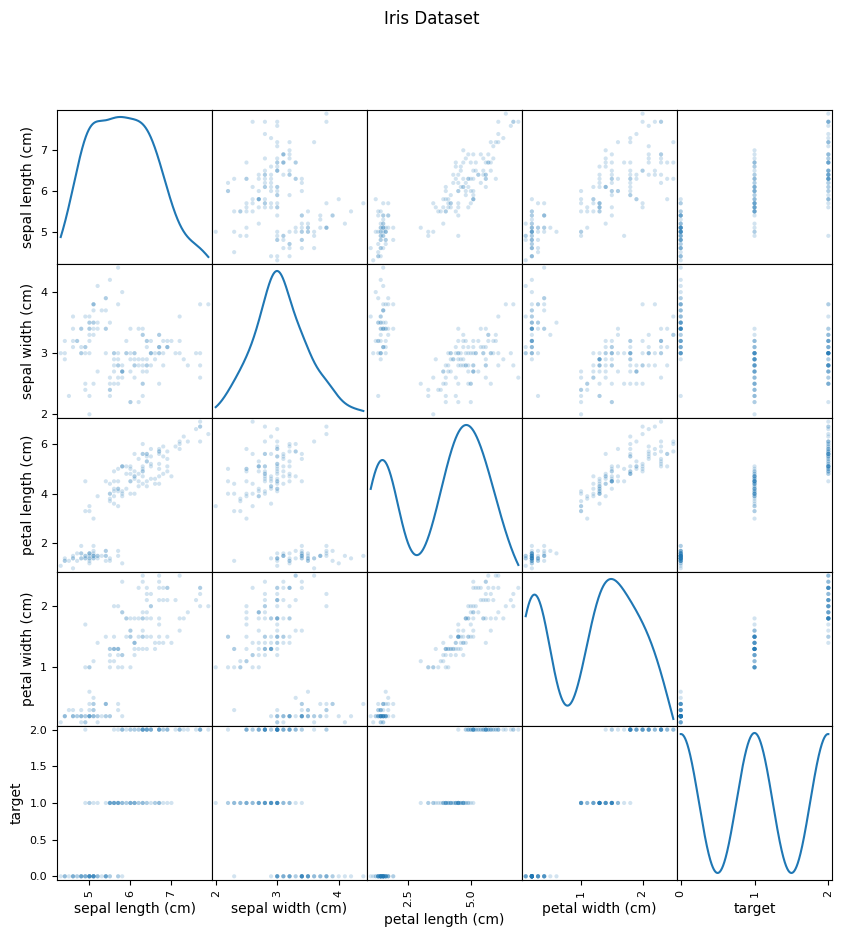

<Figure size 1000x600 with 0 Axes>

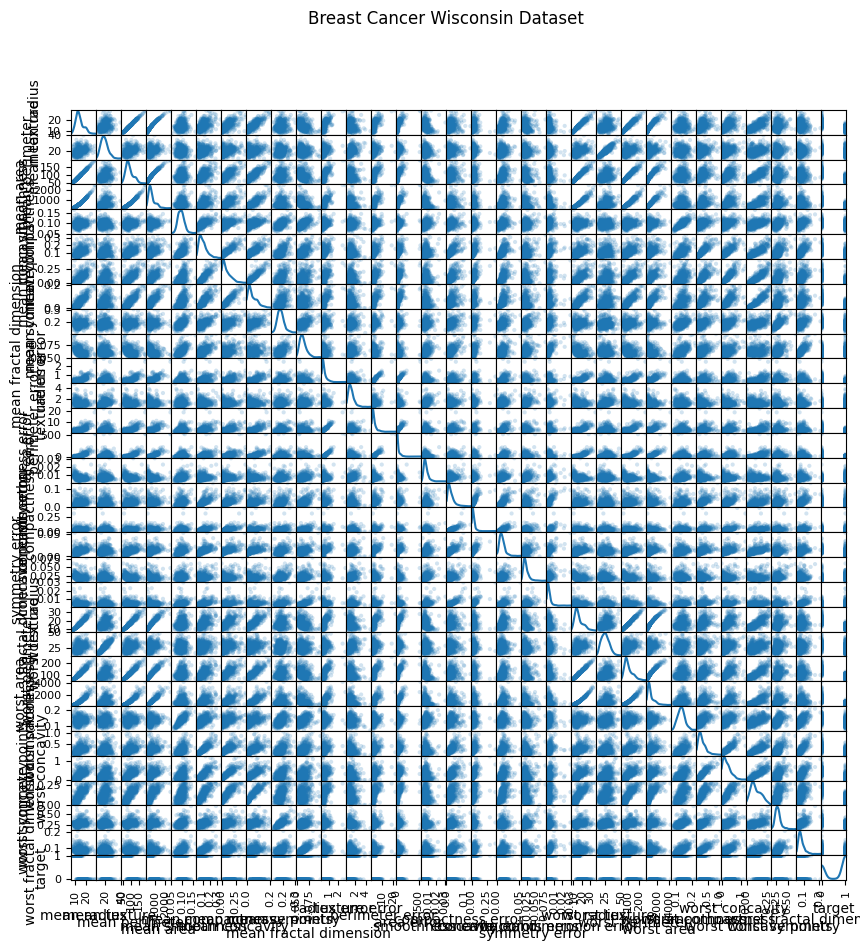

<Figure size 1000x600 with 0 Axes>

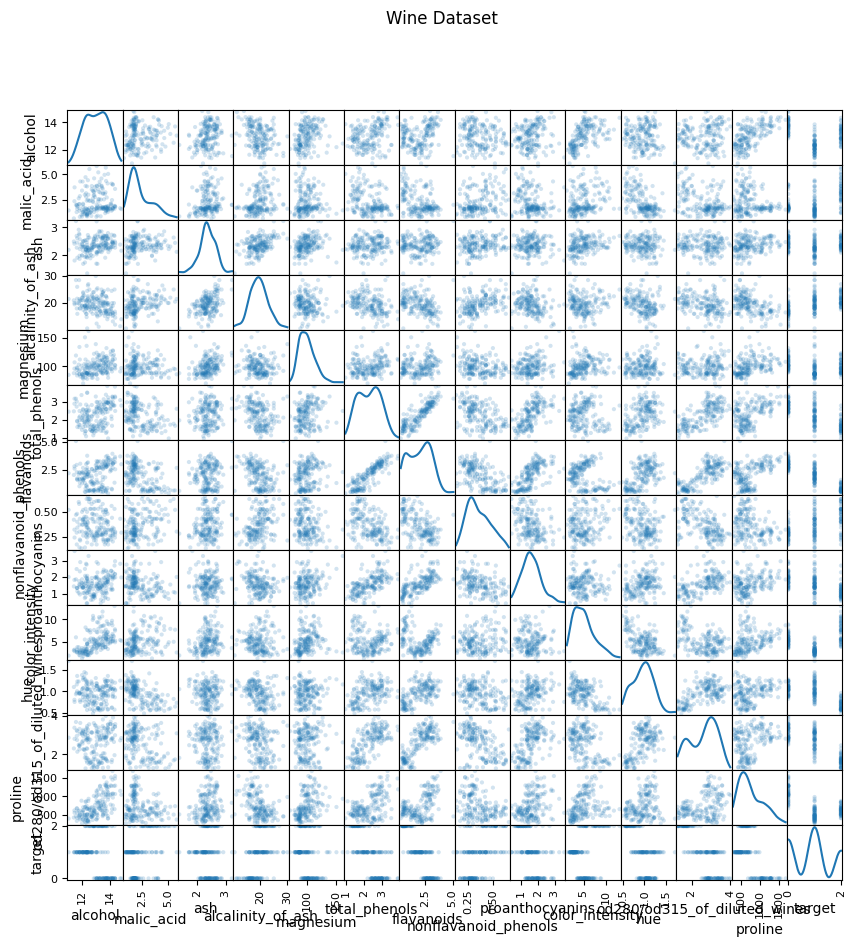

<Figure size 1000x600 with 0 Axes>

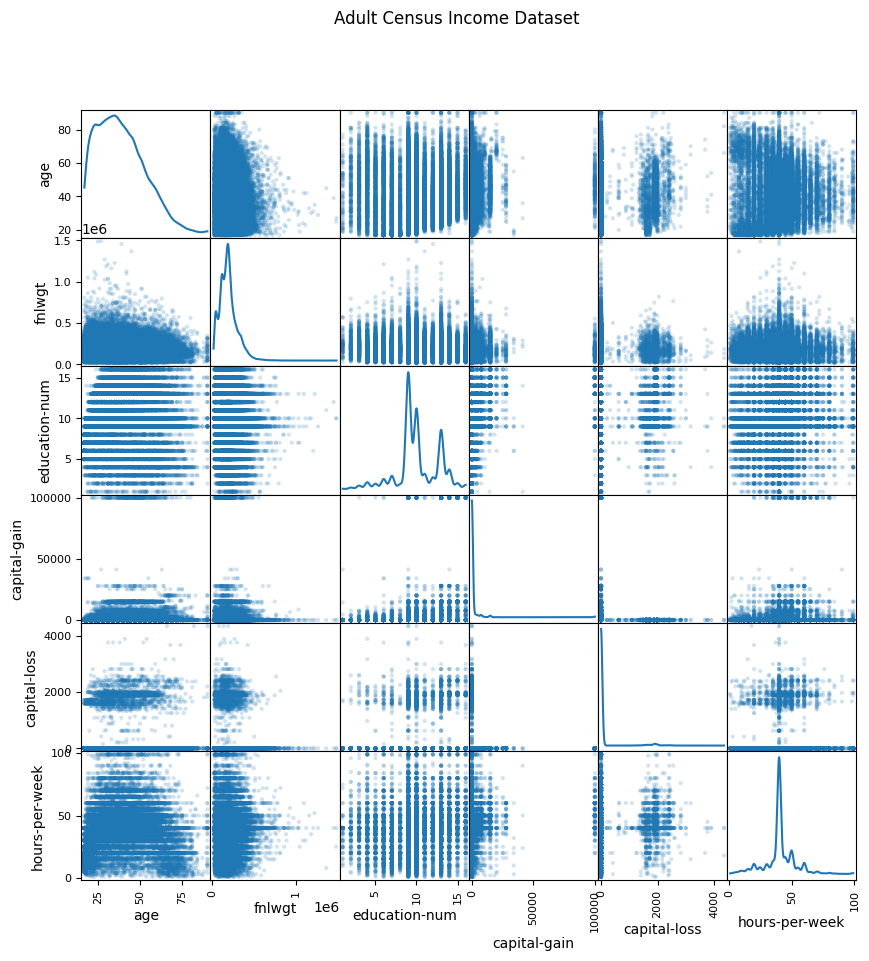

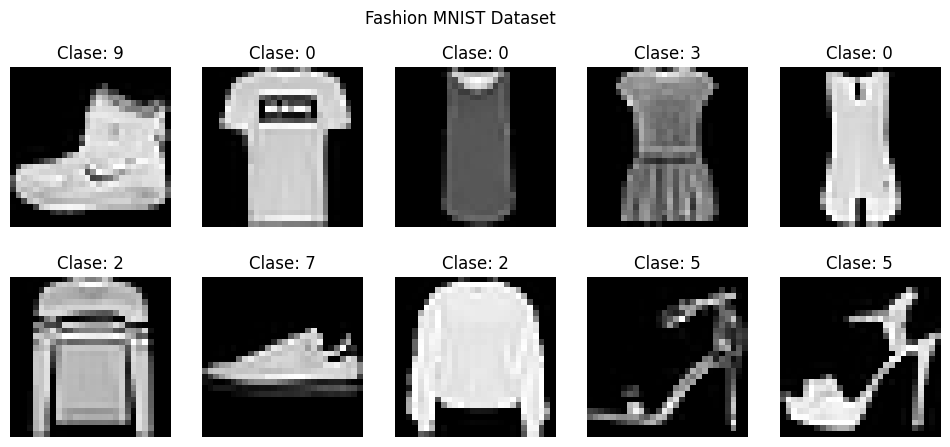

In [6]:
"""
Mostrar datasets
"""

plot_dataset(df_iris, "Iris Dataset")
plot_dataset(df_cancer, "Breast Cancer Wisconsin Dataset")
plot_dataset(df_wine, "Wine Dataset")
plot_dataset(df_adult, "Adult Census Income Dataset")
plot_fashion_mnist(df_fashion_mnist, "Fashion MNIST Dataset")

In [7]:
"""
Trabajar datos
"""
from sklearn.preprocessing import StandardScaler

# Separar características y etiquetas para cada dataset con train_test_split

# Iris dataset
X_iris = df_iris.iloc[:, :-1].to_numpy()
y_iris = df_iris.iloc[:, -1].values

# Breast Cancer Wisconsin dataset
X_cancer = df_cancer.iloc[:, :-1].to_numpy()
y_cancer = df_cancer.iloc[:, -1].values

# Wine dataset
X_wine = df_wine.iloc[:, :-1].to_numpy()
y_wine = df_wine.iloc[:, -1].values

# Adult Census Income dataset
df_adult_clean = df_adult.dropna()
X_adult = df_adult_clean.drop('class', axis=1)
y_adult = df_adult_clean['class']
X_adult_numerico = pd.get_dummies(X_adult, drop_first=True)

# Fashion MNIST dataset
X_fashion_mnist = df_fashion_mnist.iloc[:, :-1].to_numpy()
y_fashion_mnist = df_fashion_mnist.iloc[:, -1].values

# Separar los datasets en conjuntos de entrenamiento y prueba

# Iris dataset
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(X_iris, y_iris, test_size=0.2, random_state=42)

# Breast Cancer Wisconsin dataset
X_train_cancer, X_test_cancer, y_train_cancer, y_test_cancer = train_test_split(X_cancer, y_cancer, test_size=0.2, random_state=42)

# Wine dataset
X_train_wine, X_test_wine, y_train_wine, y_test_wine = train_test_split(X_wine, y_wine, test_size=0.2, random_state=42)

# Adult Census Income dataset
X_train_adult, X_test_adult, y_train_adult, y_test_adult = train_test_split(X_adult_numerico, y_adult, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_ad_scaled = scaler.fit_transform(X_train_adult)
X_test_ad_scaled = scaler.transform(X_test_adult)

# Fashion MNIST dataset
X_train_fashion_mnist, X_test_fashion_mnist, y_train_fashion_mnist, y_test_fashion_mnist = train_test_split(X_fashion_mnist, y_fashion_mnist, test_size=0.2, random_state=42)

X_train_fm_small = X_train_fashion_mnist[:5000]
y_train_fm_small = y_train_fashion_mnist[:5000]

X_test_fm_small = X_test_fashion_mnist[:1000]
y_test_fm_small = y_test_fashion_mnist[:1000]

scaler_fm = StandardScaler()
X_train_fm_scaled = scaler_fm.fit_transform(X_train_fm_small)
X_test_fm_scaled = scaler_fm.transform(X_test_fm_small)

In [8]:
from sklearn.pipeline import make_pipeline

def train_and_evaluate_model(X_train, y_train, X_test, y_test, nombre_dataset="Dataset"):
    print(f"\n{'='*10} Resultados para {nombre_dataset} {'='*10}\n")
    
    # 1. Forzar conversión a numpy arrays puros
    # Esto elimina las etiquetas de índices de Pandas y evita el KeyError
    X_train_final = np.array(X_train)
    X_test_final = np.array(X_test)
    y_train_final = np.array(y_train)
    y_test_final = np.array(y_test)

    # 2. Definición de modelos
    modelos = {
        'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier()),
        'SVC': make_pipeline(StandardScaler(), SVC()),
        'LinearSVC': make_pipeline(StandardScaler(), LinearSVC(dual='auto', max_iter=8000)),
        'NuSVC': make_pipeline(StandardScaler(), NuSVC(nu=0.1)),
        'Decision Tree': DecisionTreeClassifier(),
    }

    metricas = {
        'Modelo': [],
        'Accuracy': [],
        'Precision': [],
        'Recall': [],
        'F1 Score': [],
    }

    conf_matrices = {}

    for nombre, modelo in modelos.items():
        try:
            # Entrenar el modelo
            modelo.fit(X_train_final, y_train_final)
            
            # Hacer predicciones
            y_pred = modelo.predict(X_test_final)
            
            # Calcular métricas
            accuracy = accuracy_score(y_test_final, y_pred)
            precision = precision_score(y_test_final, y_pred, average='weighted', zero_division=0)
            recall = recall_score(y_test_final, y_pred, average='weighted', zero_division=0)
            f1 = f1_score(y_test_final, y_pred, average='weighted', zero_division=0)
            
            # Guardar métricas
            metricas['Modelo'].append(nombre)
            metricas['Accuracy'].append(accuracy)
            metricas['Precision'].append(precision)
            metricas['Recall'].append(recall)
            metricas['F1 Score'].append(f1)

            # Guardar matriz de confusión
            conf_matrices[nombre] = confusion_matrix(y_test_final, y_pred)
            
        except Exception as e:
            print(f"Error entrenando {nombre}: {e}")

    # Crear un DataFrame con las métricas
    df_metricas = pd.DataFrame(metricas)

    # Mostrar metricas por tabla
    print(df_metricas)

    # Mostrar matrices de confusión
    fig, axes = plt.subplots(1, len(modelos), figsize=(20, 4))
    
    for ax, (nombre, conf_matrix) in zip(axes, conf_matrices.items()):
        disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=np.unique(y_test_final))
        disp.plot(ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(f'{nombre}')
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
        
    plt.tight_layout()
    plt.show()


========== Resultados para Iris Dataset ==========

          Modelo  Accuracy  Precision  Recall  F1 Score
0            KNN       1.0        1.0     1.0       1.0
1            SVC       1.0        1.0     1.0       1.0
2      LinearSVC       1.0        1.0     1.0       1.0
3          NuSVC       1.0        1.0     1.0       1.0
4  Decision Tree       1.0        1.0     1.0       1.0


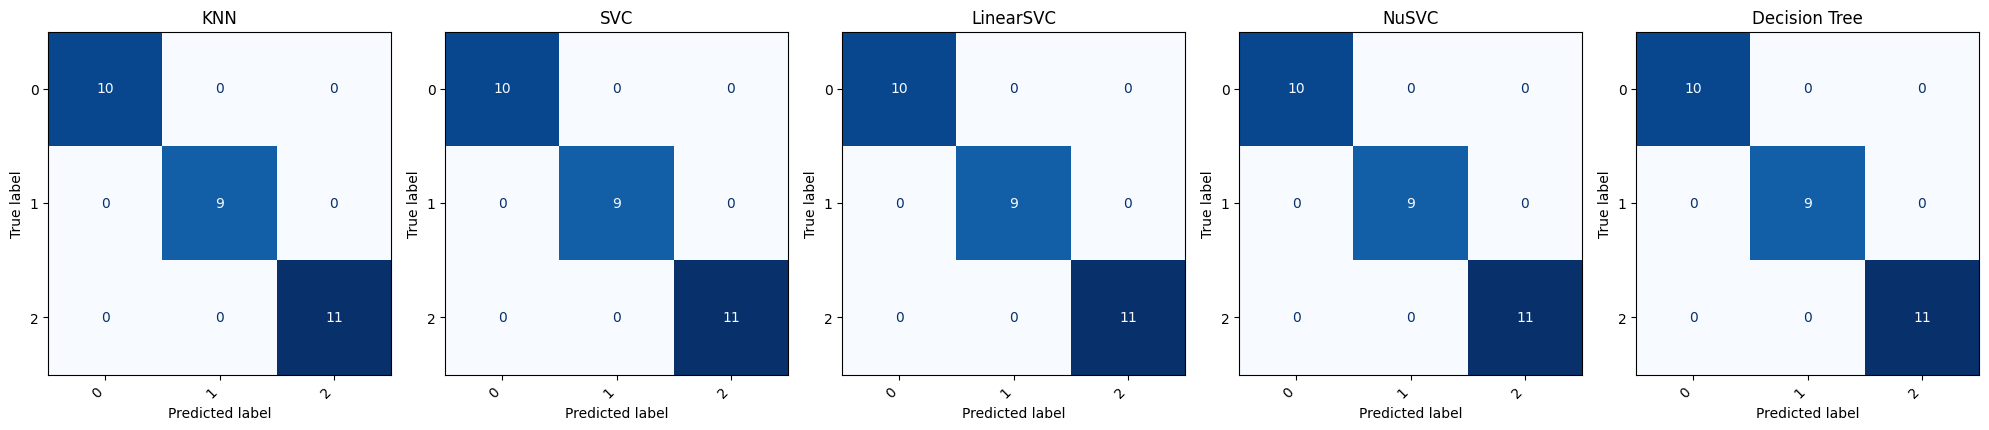


========== Resultados para Wine Dataset ==========

          Modelo  Accuracy  Precision    Recall  F1 Score
0            KNN  0.944444   0.949383  0.944444  0.943604
1            SVC  1.000000   1.000000  1.000000  1.000000
2      LinearSVC  1.000000   1.000000  1.000000  1.000000
3          NuSVC  1.000000   1.000000  1.000000  1.000000
4  Decision Tree  0.944444   0.946296  0.944444  0.943997


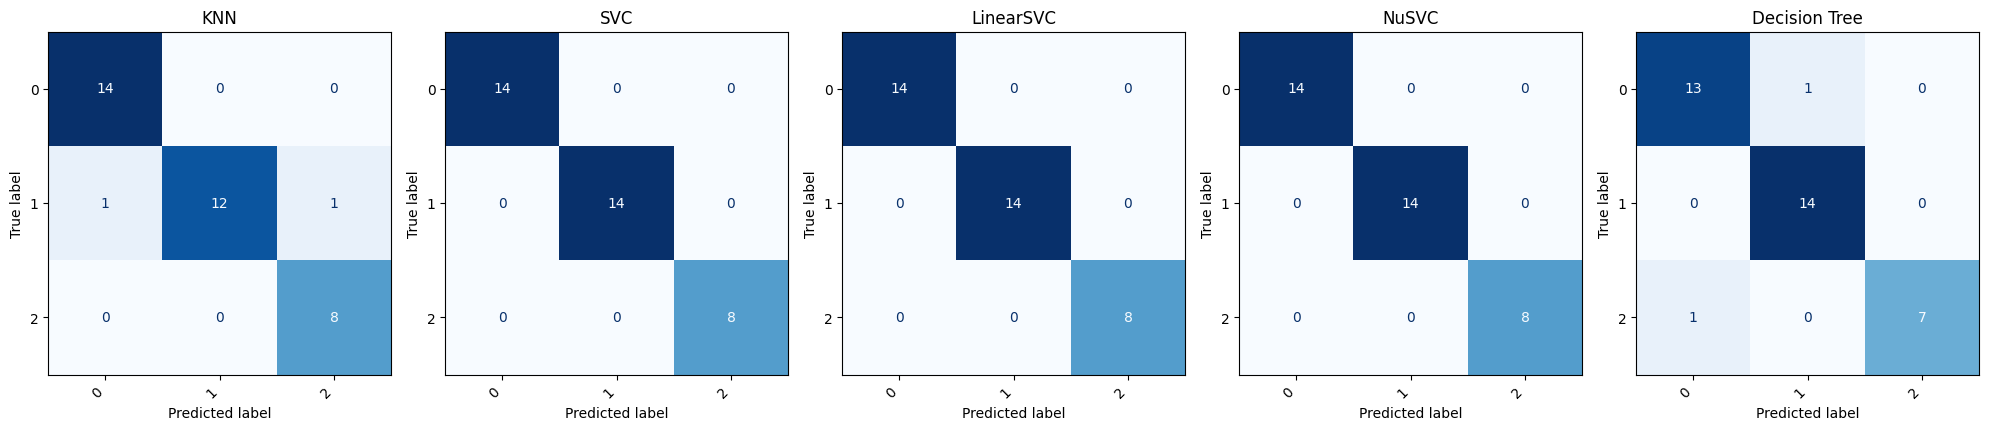


========== Resultados para Breast Cancer Dataset ==========

          Modelo  Accuracy  Precision    Recall  F1 Score
0            KNN  0.947368   0.947368  0.947368  0.947368
1            SVC  0.982456   0.982937  0.982456  0.982369
2      LinearSVC  0.956140   0.956488  0.956140  0.956237
3          NuSVC  0.982456   0.982937  0.982456  0.982369
4  Decision Tree  0.938596   0.939018  0.938596  0.938732


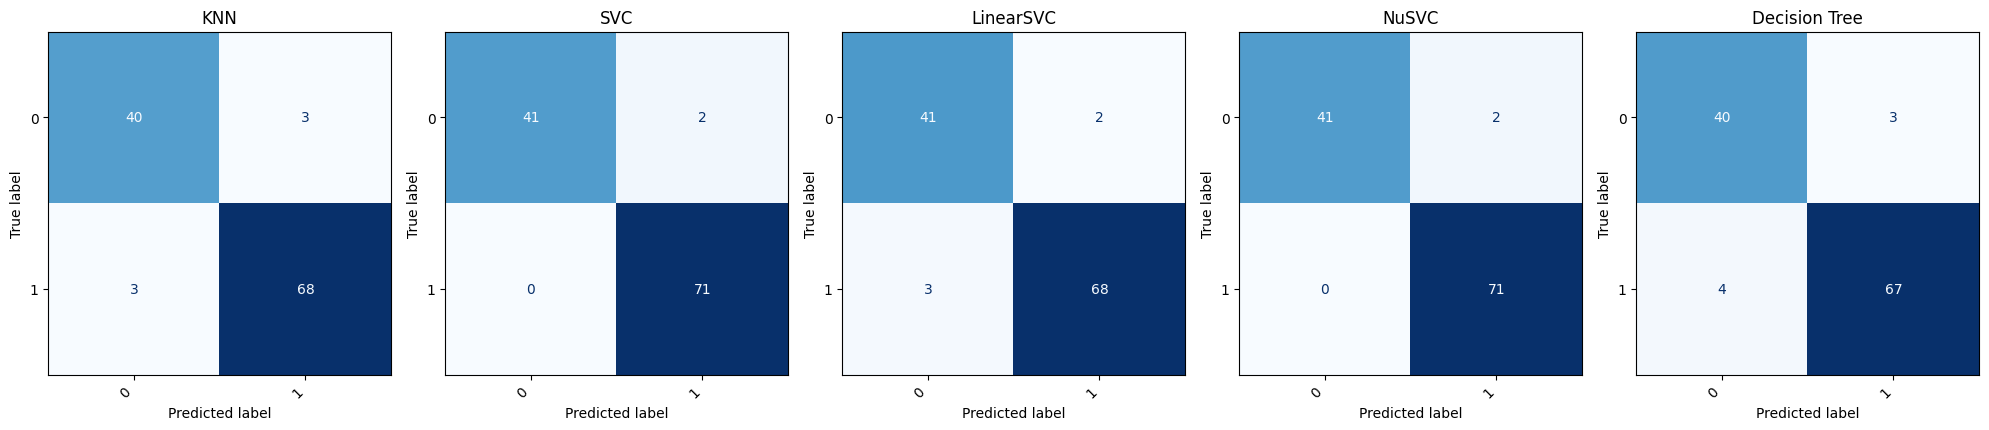


========== Resultados para Adult Census Income Dataset ==========

          Modelo  Accuracy  Precision    Recall  F1 Score
0            KNN  0.822001   0.815249  0.822001  0.817611
1            SVC  0.851962   0.845218  0.851962  0.844417
2      LinearSVC  0.852294   0.845736  0.852294  0.845960
3          NuSVC  0.779989   0.791032  0.779989  0.784590
4  Decision Tree  0.808845   0.809051  0.808845  0.808947


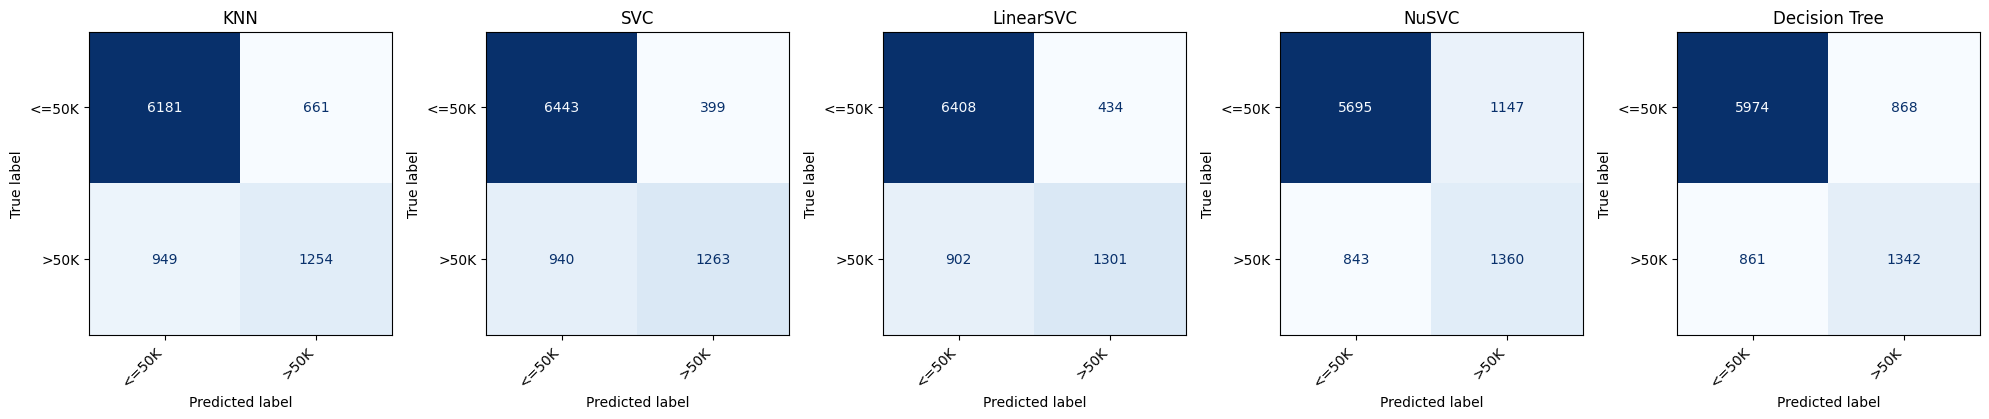


========== Resultados para Fashion MNIST Dataset ==========



c:\Users\adhev\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


          Modelo  Accuracy  Precision  Recall  F1 Score
0            KNN     0.785   0.788943   0.785  0.783293
1            SVC     0.838   0.834631   0.838  0.834362
2      LinearSVC     0.732   0.734559   0.732  0.732441
3          NuSVC     0.841   0.840484   0.841  0.840149
4  Decision Tree     0.714   0.722357   0.714  0.716986


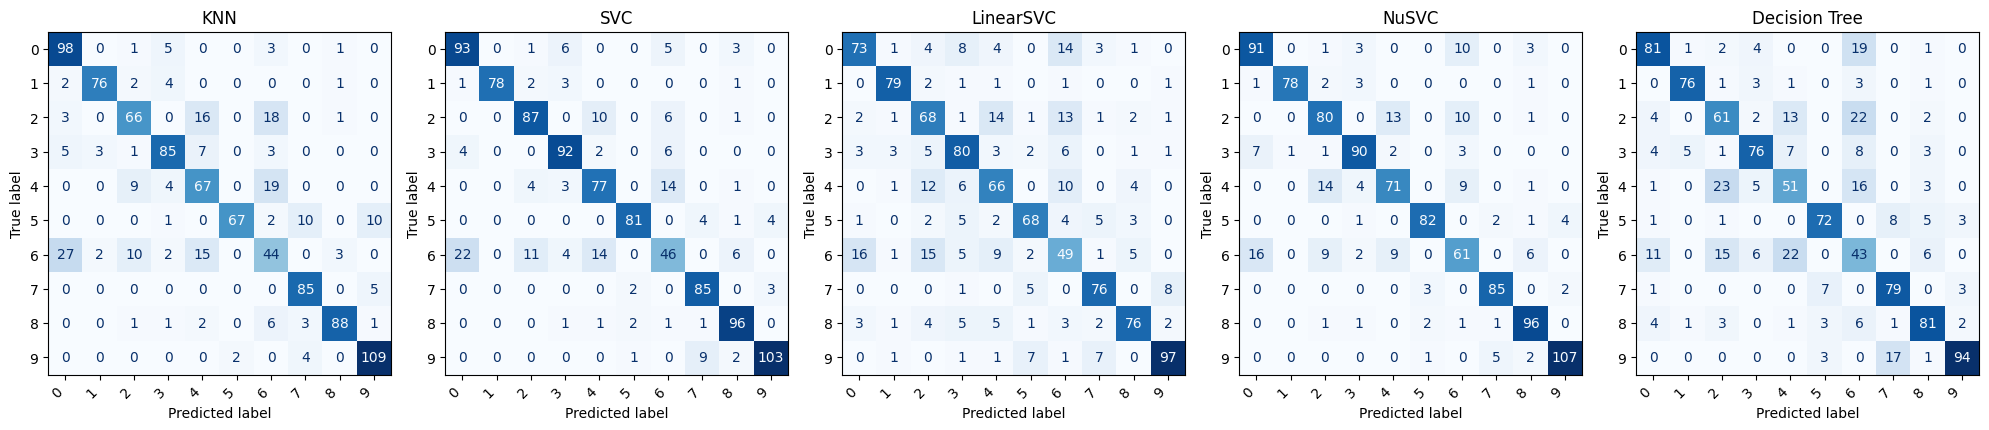

In [9]:
"""
Mostrar entrenamiento y evaluación de modelos para cada dataset
"""

train_and_evaluate_model(X_train_iris, y_train_iris, X_test_iris, y_test_iris, "Iris Dataset")

train_and_evaluate_model(X_train_wine, y_train_wine, X_test_wine, y_test_wine, "Wine Dataset")

train_and_evaluate_model(X_train_cancer, y_train_cancer, X_test_cancer, y_test_cancer, "Breast Cancer Dataset")

train_and_evaluate_model(X_train_ad_scaled, y_train_adult, X_test_ad_scaled, y_test_adult, "Adult Census Income Dataset")

train_and_evaluate_model(X_train_fm_scaled, y_train_fm_small, X_test_fm_scaled, y_test_fm_small, "Fashion MNIST Dataset")